# Scoring de crédit sur une cible simulée

Dans le premier notebook, le score de crédit du dataset est tiré au hasard, donc impossible à prédire. Ici je simule un score qui dépend du profil (endettement, épargne, dépenses, emploi) pour pouvoir entraîner un vrai modèle de scoring et vérifier qu'il retrouve les bons facteurs.

Le score simulé :
- baisse avec le DTI et avec la part des dépenses,
- monte avec l'épargne (en années de revenu) et l'âge,
- dépend du statut d'emploi,
- avec du bruit pour que ce ne soit pas parfait.

In [1]:
import sys; sys.path.append(".")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve
from src.finance_utils import load_data, add_features

plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
rng = np.random.default_rng(0)

df = add_features(load_data())
df.shape

(32424, 29)

## 1. Simulation du score

In [2]:
def z(s):
    return (s - s.mean()) / s.std()

emploi = df.employment_status.map({"Employed": 0.4, "Self-employed": 0.1, "Student": -0.2, "Unemployed": -0.6})
latent = (-1.0 * z(np.log1p(df.debt_to_income_ratio))
          + 0.6 * z(np.log(df.savings_to_income_ratio))
          - 0.5 * z(df.expense_ratio)
          + 0.3 * z(df.age)
          + emploi
          + rng.normal(0, 0.8, len(df)))
df["credit_score_sim"] = (300 + 550 / (1 + np.exp(-latent))).round().astype(int)
df["good_credit"] = (df.credit_score_sim >= 670).astype(int)

print(df.credit_score_sim.describe().round(1))
print("Part de bons dossiers :", round(df.good_credit.mean(), 3))

count    32424.0
mean       599.9
std        150.0
min        300.0
25%        478.0
50%        621.0
75%        730.0
max        845.0
Name: credit_score_sim, dtype: float64
Part de bons dossiers : 0.397


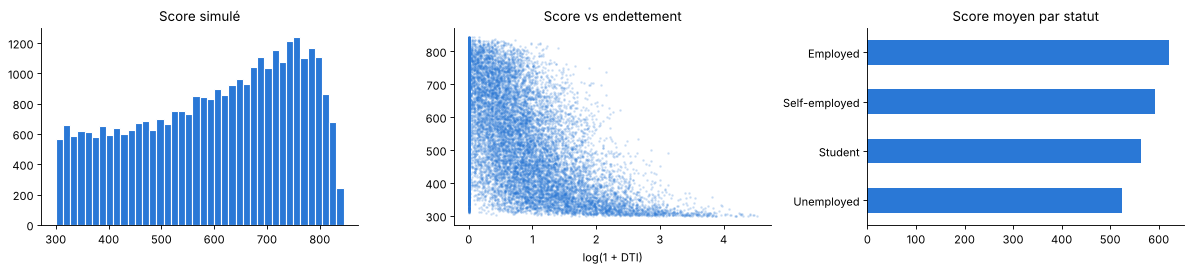

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(df.credit_score_sim, bins=40, color=BLUE, edgecolor="white")
axes[0].set_title("Score simulé")
axes[1].scatter(np.log1p(df.debt_to_income_ratio), df.credit_score_sim, s=2, alpha=0.15, color=BLUE)
axes[1].set_xlabel("log(1 + DTI)"); axes[1].set_title("Score vs endettement")
df.groupby("employment_status").credit_score_sim.mean().sort_values().plot.barh(ax=axes[2], color=BLUE)
axes[2].set_title("Score moyen par statut"); axes[2].set_ylabel("")
plt.tight_layout(); plt.show()

## 2. Modèles

Même split temporel que dans le notebook 1 (train avant juillet 2024). Les variables sont celles qu'un organisme de crédit connaîtrait : revenus, dépenses, épargne, dettes en cours, emploi. Le genre et la région ne sont pas utilisés.

In [4]:
CUTOFF = pd.Timestamp("2024-07-01")
df["log_dti"] = np.log1p(df.debt_to_income_ratio)
train, test = df[df.record_date < CUTOFF], df[df.record_date >= CUTOFF]
NUM = ["age", "log_income", "expense_ratio", "log_savings", "savings_to_income_ratio", "log_dti", "has_loan"]
CAT = ["employment_status", "education_level"]
pre = ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

models = {
    "Baseline": DummyClassifier(strategy="prior"),
    "Régression logistique": Pipeline([("pre", pre), ("m", LogisticRegression(max_iter=1000))]),
    "Gradient boosting": Pipeline([("pre", pre), ("m", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0))]),
}
scores = {}
for name, m in models.items():
    m.fit(train[NUM + CAT], train.good_credit)
    scores[name] = m.predict_proba(test[NUM + CAT])[:, 1]
res = pd.Series({k: roc_auc_score(test.good_credit, v) for k, v in scores.items()}, name="AUC test")
res.round(3)

Baseline                 0.500
Régression logistique    0.892
Gradient boosting        0.887
Name: AUC test, dtype: float64

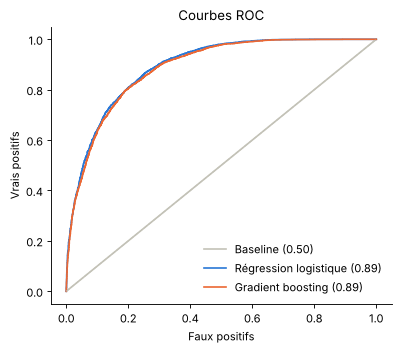

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for (name, s), col in zip(scores.items(), [GREY, BLUE, ORANGE]):
    fpr, tpr, _ = roc_curve(test.good_credit, s)
    ax.plot(fpr, tpr, color=col, label=f"{name} ({res[name]:.2f})")
ax.plot([0, 1], [0, 1], ls="--", color=GREY, lw=1)
ax.set_xlabel("Faux positifs"); ax.set_ylabel("Vrais positifs"); ax.set_title("Courbes ROC"); ax.legend(frameon=False)
plt.show()

Cette fois les modèles font nettement mieux que la baseline. La régression logistique est aussi bonne que le gradient boosting, ce qui est logique : le score a été simulé avec une formule presque linéaire.

## 3. Quelles variables comptent ?

Importance par permutation sur le jeu de test : on mélange une variable et on regarde combien l'AUC baisse.

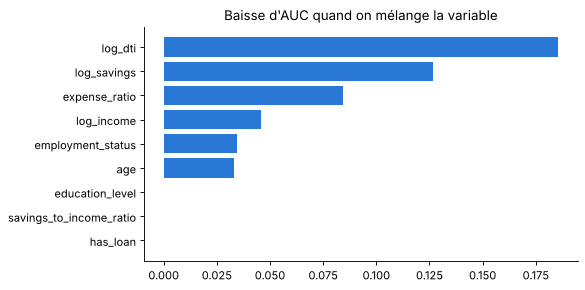

log_dti                    0.1855
log_savings                0.1268
expense_ratio              0.0842
log_income                 0.0460
employment_status          0.0344
age                        0.0332
education_level            0.0000
savings_to_income_ratio   -0.0000
has_loan                  -0.0000
dtype: float64

In [6]:
logit = models["Régression logistique"]
imp = permutation_importance(logit, test[NUM + CAT], test.good_credit, scoring="roc_auc", n_repeats=5, random_state=0)
imp = pd.Series(imp.importances_mean, index=NUM + CAT).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp.values, color=BLUE); ax.set_title("Baisse d'AUC quand on mélange la variable")
plt.show()
imp.sort_values(ascending=False).round(4)

Le modèle retrouve les facteurs utilisés dans la simulation : l'endettement en premier, puis l'épargne, les dépenses, l'emploi et l'âge. Le niveau d'études, qui n'entre pas dans la formule, n'apporte rien. Le revenu ressort un peu alors qu'il n'est pas dans la formule : c'est parce que le modèle reconstruit le ratio épargne/revenu à partir de log(épargne) - log(revenu).